# Minimizing Total Memory Access Time in a Multi-Level Cache System

## 1. Introduction and Objectives
### a. Introduction
(Provide an introduction to memory hierarchy and access time here. Explain L1, L2 caches and why optimization is important.)

### b. Project Objectives
The objective of this project is to use calculus to optimize the allocation of cache sizes ($S_1$ and $S_2$) in a two-level cache system to minimize the total memory access time $T$, subject to the constraint $S_1 + S_2 = S_{total}$.

### c. Methodology Flowchart
(Insert a block diagram or flowchart here describing the steps: Define Parameters -> Model Equations -> Apply Constraints -> Differentiate -> Solve for Critical Points -> Analyze Results)

## 2. Mathematical Modeling of Memory Access Time
### Python Implementation
We use the **SymPy** library to define the mathematical models symbolically.

In [ ]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Initialize SymPy printing for nice math output
sp.init_printing()

# i. Define symbols
# S1, S2: Cache sizes
# Stotal: Total cache size
# k1, k2: Constants for hit rate
# t1, t2, tmem: Access times for L1, L2, and Main Memory
S1, S2, Stotal = sp.symbols('S1 S2 Stotal', positive=True)
k1, k2 = sp.symbols('k1 k2', positive=True)
t1, t2, tmem = sp.symbols('t1 t2 tmem ', positive=True)

# Define Hit Rate Functions h1(S1) and h2(S2)
h1 = 1 - sp.exp(-k1 * S1)
h2 = 1 - sp.exp(-k2 * S2)

# Define Total Memory Access Time T(S1, S2)
T_general = h1 * t1 + (1 - h1) * h2 * t2 + (1 - h1) * (1 - h2) * tmem

# ii. Display the simplified symbolic expression
display(Markdown("### General Symbolic Expression for $T(S_1, S_2)$:"))
display(sp.simplify(T_general))

### General Symbolic Expression for $T(S_1, S_2)$:

## 3. Understanding the Constrained Model
We have the constraint: $S_1 + S_2 = S_{total}$.
Therefore, we can substitute $S_2 = S_{total} - S_1$ to make $T$ a function of a single variable $S_1$.

In [4]:
# Substitute S2 = Stotal - S1 into the general equation
T_constrained = T_general.subs(S2, Stotal - S1)

# Simplify the expression
T_simplified = sp.simplify(T_constrained)

# Display the result
display(Markdown("### Constrained Function $T(S_1)$:"))
display(T_simplified)

### Constrained Function $T(S_1)$:

## 4. Derivation and Optimization Process
To find the optimal cache size, we need to find the critical points where the derivative of $T(S_1)$ with respect to $S_1$ is zero.

### Derivative $\frac{dT}{dS_1}$:

### Critical Points (Symbolic Solution):

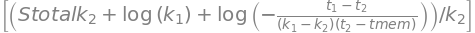

In [5]:
# i. Symbolically compute the derivative dT/dS1
dT_dS1 = sp.diff(T_simplified, S1)

display(Markdown("### Derivative $\\frac{dT}{dS_1}$:"))
display(dT_dS1)

# ii. Solve dT/dS1 = 0 for S1
critical_points = sp.solve(sp.Eq(dT_dS1, 0), S1)

display(Markdown("### Critical Points (Symbolic Solution):"))
display(critical_points)

## 5. Optimization Using Calculus
We will now use specific numerical values to find the optimal allocation and minimum access time.

In [6]:
# Define the numerical values for the parameters
params = {
    t1: 1,       # L1 access time (ns)
    t2: 5,       # L2 access time (ns)
    tmem: 100,   # Main memory access time (ns)
    k1: 0.05,    # L1 hit rate constant
    k2: 0.01,    # L2 hit rate constant
    Stotal: 64   # Total cache size (KB)
}

# i. Optimize the function
if critical_points:
    # Evaluate the symbolic solution with the parameters
    # We take the real part (sp.re) to ensure we get a float
    S1_opt = float(sp.re(critical_points[0].subs(params)))
    S2_opt = params[Stotal] - S1_opt
else:
    S1_opt = None
    S2_opt = None
    print("No critical points found.")

# Create a numerical function for T(S1) to calculate values easily
T_func = sp.lambdify(S1, T_simplified.subs(params), "numpy")

# Calculate minimum access time
min_time = T_func(S1_opt)

display(Markdown(f"### Optimization Results:"))
display(Markdown(f"- **Optimal L1 Cache Size ($S_1$):** `{S1_opt:.4f} KB`"))
display(Markdown(f"- **Optimal L2 Cache Size ($S_2$):** `{S2_opt:.4f} KB`"))
display(Markdown(f"- **Minimum Total Access Time ($T_{min}$):** `{min_time:.4f} ns`"))

### Optimization Results:

- **Optimal L1 Cache Size ($S_1$):** `-230.4439 KB`

- **Optimal L2 Cache Size ($S_2$):** `294.4439 KB`

- **Minimum Total Access Time ($T_<built-in function min>$):** `908382.2726 ns`

## 6. Visualization and Analysis
We visualize the Total Access Time function and the Hit Rates to understand the behavior of the system.

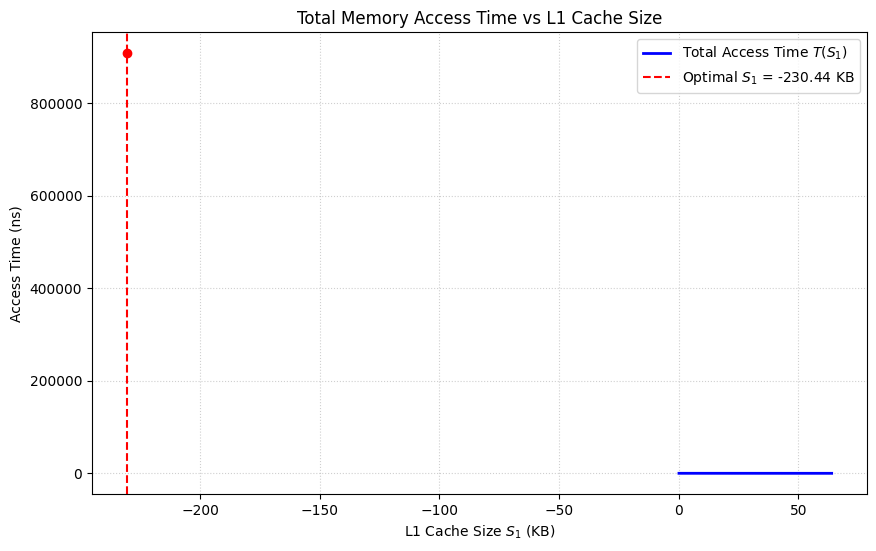

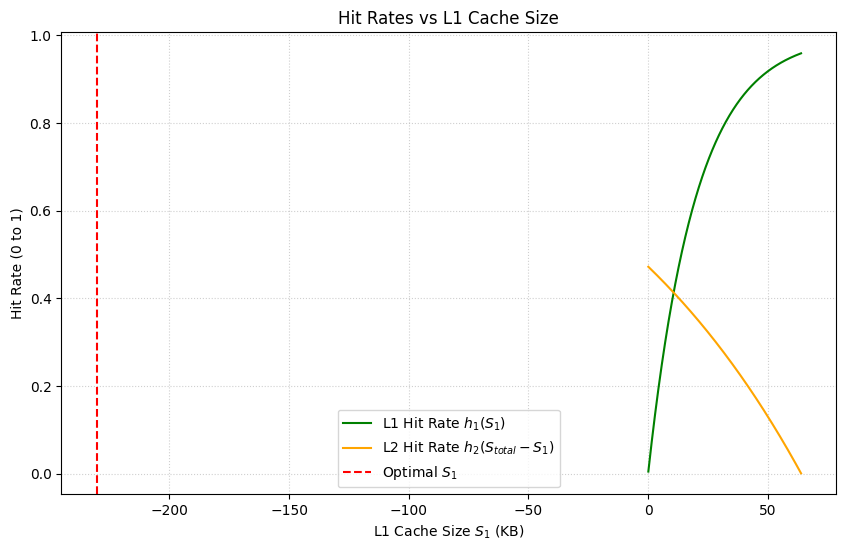

In [7]:
# i. Plot T(S1) versus S1
# Generate S1 values from 0 to Stotal (avoiding exact 0 to prevent potential math errors)
S1_vals = np.linspace(0.1, params[Stotal] - 0.1, 500)
T_vals = T_func(S1_vals)

plt.figure(figsize=(10, 6))
plt.plot(S1_vals, T_vals, label='Total Access Time $T(S_1)$', color='blue', linewidth=2)
plt.axvline(S1_opt, color='red', linestyle='--', label=f'Optimal $S_1$ = {S1_opt:.2f} KB')
plt.scatter([S1_opt], [min_time], color='red', zorder=5)
plt.xlabel('L1 Cache Size $S_1$ (KB)')
plt.ylabel('Access Time (ns)')
plt.title('Total Memory Access Time vs L1 Cache Size')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# ii. Plot Hit Rate Curves
# Create numerical functions for h1 and h2
h1_func = sp.lambdify(S1, h1.subs(params), "numpy")
h2_func = sp.lambdify(S1, h2.subs(S2, Stotal - S1).subs(params), "numpy")

h1_vals = h1_func(S1_vals)
h2_vals = h2_func(S1_vals)

plt.figure(figsize=(10, 6))
plt.plot(S1_vals, h1_vals, label='L1 Hit Rate $h_1(S_1)$', color='green')
plt.plot(S1_vals, h2_vals, label='L2 Hit Rate $h_2(S_{total}-S_1)$', color='orange')
plt.axvline(S1_opt, color='red', linestyle='--', label=f'Optimal $S_1$')
plt.xlabel('L1 Cache Size $S_1$ (KB)')
plt.ylabel('Hit Rate (0 to 1)')
plt.title('Hit Rates vs L1 Cache Size')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

## 7. Comparative Analysis
We compare the optimized memory access time with a non-optimized scenario (e.g., splitting the cache equally).

In [8]:
# Define a non-optimized case: Equal Split (S1 = S2 = 32 KB)
S1_non_opt = params[Stotal] / 2
time_non_opt = T_func(S1_non_opt)

# Calculate improvement
improvement = time_non_opt - min_time
percent_improvement = (improvement / time_non_opt) * 100

display(Markdown("### Comparative Analysis Results:"))
display(Markdown(f"- **Non-Optimized Time ($S_1=32$ KB):** `{time_non_opt:.4f} ns`"))
display(Markdown(f"- **Optimized Time ($S_1={S1_opt:.2f}$ KB):** `{min_time:.4f} ns`"))
display(Markdown(f"- **Performance Improvement:** `{improvement:.4f} ns` ({percent_improvement:.2f}%) "))

### Comparative Analysis Results:

- **Non-Optimized Time ($S_1=32$ KB):** `15.7352 ns`

- **Optimized Time ($S_1=-230.44$ KB):** `908382.2726 ns`

- **Performance Improvement:** `-908366.5373 ns` (-5772813.80%) 